In [66]:
!git clone https://github.com/quanhua92/human-pose-estimation-opencv.git

fatal: destination path 'human-pose-estimation-opencv' already exists and is not an empty directory.


In [67]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# **Body parts and its pairs**

! [Image for as an example](human-pose-estimation-opencv\image.jpg)

In [68]:
BODY_PARTS = { "Nose": 0, "Neck": 1, "RShoulder": 2, "RElbow": 3, "RWrist": 4,
               "LShoulder": 5, "LElbow": 6, "LWrist": 7, "RHip": 8, "RKnee": 9,
               "RAnkle": 10, "LHip": 11, "LKnee": 12, "LAnkle": 13, "REye": 14,
               "LEye": 15, "REar": 16, "LEar": 17, "Background": 18 }

POSE_PAIRS = [ ["Neck", "RShoulder"], ["Neck", "LShoulder"], ["RShoulder", "RElbow"],
               ["RElbow", "RWrist"], ["LShoulder", "LElbow"], ["LElbow", "LWrist"],
               ["Neck", "RHip"], ["RHip", "RKnee"], ["RKnee", "RAnkle"], ["Neck", "LHip"],
               ["LHip", "LKnee"], ["LKnee", "LAnkle"], ["Neck", "Nose"], ["Nose", "REye"],
               ["REye", "REar"], ["Nose", "LEye"], ["LEye", "LEar"] ]


In [69]:
img_path = "human-pose-estimation-opencv\image.jpg"
img_width = 368
img_height = 368
threshold = 0.1

# **Weights for openpose model**

In [70]:
net = cv.dnn.readNetFromTensorflow(model="human-pose-estimation-opencv\graph_opt.pb")

In [71]:
img = cv.imread(img_path)

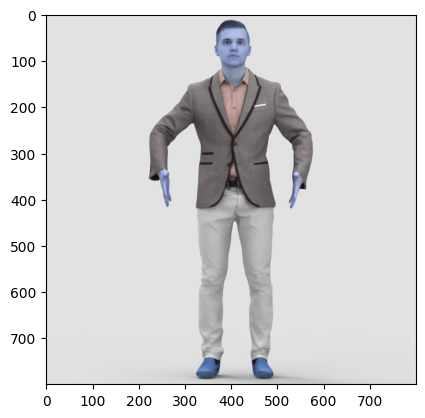

In [72]:
plt.imshow(img)

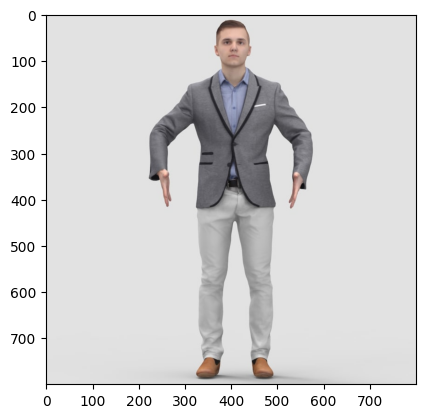

In [73]:
plt.imshow(cv.cvtColor(img,cv.COLOR_BGR2RGB))

In [74]:
def pose_estimatiom(img):
    
    img_width = img.shape[1]
    img_height = img.shape[0]
    
    net.setInput(cv.dnn.blobFromImage(image=img,scalefactor=1.0,size=(img_width,img_height),mean=(127.5,127.5,127.5),swapRB=True,crop=False))
    
    output = net.forward()
    
    output = output[:,:19,:,:]#[batch,num_keypoints,height,width] it can able to detect 25 points
    assert(len(BODY_PARTS) == output.shape[1])
    
    points = []
    
    
    for i in range(len(BODY_PARTS)):
        
        heatmap = output[0,i,:,:]
        
        _,conf,_,point = cv.minMaxLoc(src=heatmap)
        
        x = (img_width * point[0]) / output.shape[3]
        y = (img_height * point[1]) / output.shape[2]
        
        points.append((int(x) , int(y)) if conf > threshold else None)
        
        
    for pair in POSE_PAIRS:
        
        PART_FROM = pair[0]       
        PART_TO =  pair[1]
        
        assert(PART_FROM in BODY_PARTS)
        assert(PART_TO in BODY_PARTS)
        
        
        ID_FROM = BODY_PARTS[PART_FROM]
        ID_TO = BODY_PARTS[PART_TO]
        
        if points[ID_FROM] and points[ID_TO]:
            cv.line(img, points[ID_FROM], points[ID_TO], (0, 255, 0), 3)
            cv.ellipse(img, points[ID_FROM], (3, 3), 0, 0, 360, (0, 0, 255), cv.FILLED)
            cv.ellipse(img, points[ID_TO], (3, 3), 0, 0, 360, (0, 0, 255), cv.FILLED)
            
    freq,timings = net.getPerfProfile() #total timings take for forward pass,excution time of every layer
    
    freq_per_second = cv.getTickFrequency()/1000
    
    cv.putText(img, '%.2fms' % (freq / freq_per_second), (10, 20), cv.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0))

    return img
    

In [75]:
estimated_img = pose_estimatiom(img)

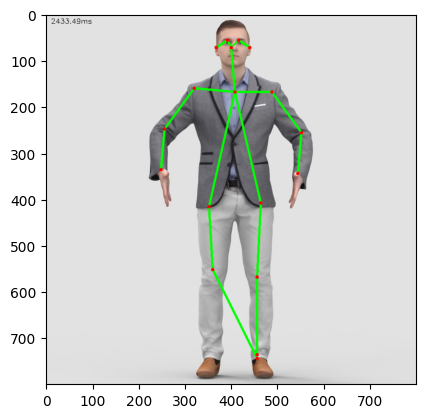

In [76]:
plt.imshow(cv.cvtColor(estimated_img,cv.COLOR_BGR2RGB))